# Lab 08: Two-Layer Neural Network Forward Pass

**Course:** Deep Learning for Computer Vision — 2026  
**Lecture connection:** Lecture 5A

Implement the forward pass of a two-layer neural network, inspect its hidden activations and class scores, and see why the ReLU activation changes what stacked layers can represent.

## 1. Setup

Keep the notebook, `two_layer_net.py`, and the `dlcv2026` directory together. In Google Colab, upload the complete `Lab08` folder before opening the notebook. Run the setup cell again after editing `two_layer_net.py`.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import torch

candidate_dirs = [
    Path.cwd(),
    Path.cwd() / 'Lab08',
    Path.cwd() / 'DNN' / 'Lab08',
    Path.cwd() / 'Labs' / 'DNN' / 'Lab08',
    Path.cwd() / 'Deep-Learning-for-Computer-Vision' / 'Labs' / 'DNN' / 'Lab08',
]
lab_dir = next(
    (
        path.resolve()
        for path in candidate_dirs
        if (path / 'two_layer_net.py').is_file()
        and (path / 'dlcv2026').is_dir()
    ),
    None,
)
if lab_dir is None:
    raise FileNotFoundError(
        'Could not find the Lab08 support files. Keep two_layer_net.py '
        'and the dlcv2026 folder together with the notebook.'
    )

if str(lab_dir) not in sys.path:
    sys.path.insert(0, str(lab_dir))
for module_name in tuple(sys.modules):
    if (
        module_name == 'two_layer_net'
        or module_name == 'dlcv2026'
        or module_name.startswith('dlcv2026.')
    ):
        del sys.modules[module_name]

import dlcv2026
import two_layer_net

importlib.reload(two_layer_net)
torch.set_default_dtype(torch.float64)
torch.manual_seed(0)

print('PyTorch:', torch.__version__)
print('Lab directory:', lab_dir)
print('Implementation:', Path(two_layer_net.__file__).resolve())


PyTorch: 2.5.1+cpu
Lab directory: C:\Users\student\Desktop\Lab08
Implementation: C:\Users\student\Desktop\Lab08\two_layer_net.py


## 2. Forward pass

For a minibatch \(X\) with shape \((N,D)\), the network has hidden width \(H\) and \(C\) output classes:

\[
Z_1 = XW_1 + b_1; H = \operatorname{ReLU}(Z_1); S = HW_2 + b_2.
\]

The rows of \(S\) are class-score vectors. The predicted class is the index of the largest score in each row.

In [2]:
fixture = dlcv2026.make_forward_fixture()
X = fixture['X']
params = fixture['params']

print('X shape:', tuple(X.shape))
for name, value in params.items():
    print(f'{name} shape:', tuple(value.shape))


X shape: (2, 3)
W1 shape: (3, 4)
b1 shape: (4,)
W2 shape: (4, 3)
b2 shape: (3,)


## 3. Exercise 1 — ReLU

Complete `relu` in `two_layer_net.py`. It must set negative entries to zero while leaving positive entries unchanged. Save the file, then run the check below.

In [3]:
importlib.reload(two_layer_net)

values = torch.tensor([[-2.0, 0.0, 1.5], [3.0, -0.5, -4.0]])
activated = two_layer_net.relu(values)
expected = torch.tensor([[0.0, 0.0, 1.5], [3.0, 0.0, 0.0]])

print('ReLU output:\n', activated)
assert torch.equal(activated, expected)
print('ReLU check passed.')


ReLU output:
 tensor([[0.0000, 0.0000, 1.5000],
        [3.0000, 0.0000, 0.0000]])
ReLU check passed.


## 4. Exercise 2 — Two-layer scores

Complete `two_layer_forward` in `two_layer_net.py`. First compute \(Z_1\), apply your `relu`, then compute the output scores. Use matrix multiplication; for the tensors in this lab, `X @ W` and `torch.matmul(X, W)` are equivalent.

In [4]:
importlib.reload(two_layer_net)

scores, hidden = two_layer_net.two_layer_forward(params, X)
print('hidden activations:\n', hidden)
print('scores:\n', scores)

assert torch.allclose(hidden, fixture['expected_hidden'])
assert torch.allclose(scores, fixture['expected_scores'])
print('Forward-pass check passed.')


hidden activations:
 tensor([[0.5000, 0.5000, 3.0000, 0.0000],
        [1.5000, 2.5000, 0.0000, 0.0000]])
scores:
 tensor([[ 3.7000, -0.1000, -2.2000],
        [ 1.7000,  0.9000,  2.8000]])
Forward-pass check passed.


## 5. Exercise 3 — Predictions from scores

Complete `predict_two_layer`. For each example, return the class index with the largest score.

In [5]:
importlib.reload(two_layer_net)

predictions = two_layer_net.predict_two_layer(params, X)
print('predicted classes:', predictions.tolist())
assert torch.equal(predictions, fixture['expected_predictions'])
print('Prediction check passed.')


predicted classes: [0, 2]
Prediction check passed.


## 6. Why the activation matters

Without an activation, two fully connected layers collapse into one:

\[
(XW_1)W_2 = X(W_1W_2).
\]

The check below verifies this identity for a small batch. ReLU between the layers prevents this collapse.

In [6]:
X_linear, W1_linear, W2_linear = dlcv2026.make_linear_equivalence_fixture()
two_linear_layers = (X_linear @ W1_linear) @ W2_linear
one_linear_layer = X_linear @ (W1_linear @ W2_linear)

print('maximum difference:', (two_linear_layers - one_linear_layer).abs().max().item())
assert torch.allclose(two_linear_layers, one_linear_layer)


maximum difference: 0.0


## 7. A fixed nonlinear classifier

The supplied network uses four ReLU units to form \(|x_1|\) and \(|x_2|\). Its first score is \(1-|x_1|-|x_2|\), so class 0 is selected inside a diamond-shaped region. There is no training in this example; the weights are fixed so that we can inspect the forward computation directly.

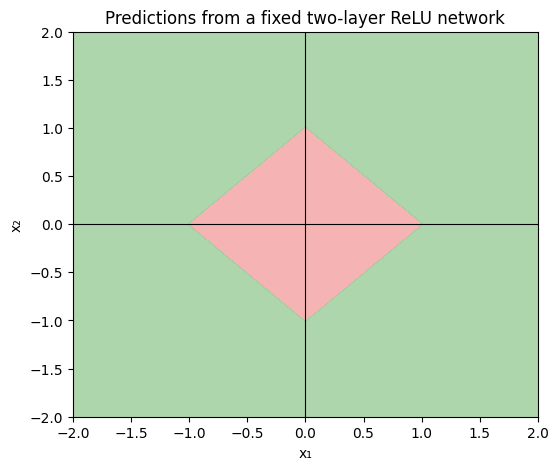

In [7]:
importlib.reload(two_layer_net)

demo_params = dlcv2026.make_diamond_network()
grid_points, grid_x, grid_y = dlcv2026.make_input_grid()
grid_predictions = two_layer_net.predict_two_layer(demo_params, grid_points)

plt.figure(figsize=(6, 5))
plt.contourf(
    grid_x.numpy(),
    grid_y.numpy(),
    grid_predictions.reshape(grid_x.shape).numpy(),
    levels=[-0.5, 0.5, 1.5],
    colors=['#f4a6a6', '#9fcf9f'],
    alpha=0.85,
)
plt.axhline(0.0, color='black', linewidth=0.8)
plt.axvline(0.0, color='black', linewidth=0.8)
plt.xlabel('x₁')
plt.ylabel('x₂')
plt.title('Predictions from a fixed two-layer ReLU network')
plt.show()


In [8]:
probe_points = torch.tensor([[0.0, 0.0], [0.5, 0.25], [1.25, 0.25], [-0.5, -0.75]])
probe_scores, probe_hidden = two_layer_net.two_layer_forward(
    demo_params, probe_points
)

print('probe points:\n', probe_points)
print('hidden activations:\n', probe_hidden)
print('scores:\n', probe_scores)
print('predictions:', probe_scores.argmax(dim=1).tolist())


probe points:
 tensor([[ 0.0000,  0.0000],
        [ 0.5000,  0.2500],
        [ 1.2500,  0.2500],
        [-0.5000, -0.7500]])
hidden activations:
 tensor([[0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.0000, 0.2500, 0.0000],
        [1.2500, 0.0000, 0.2500, 0.0000],
        [0.0000, 0.5000, 0.0000, 0.7500]])
scores:
 tensor([[ 1.0000,  0.0000],
        [ 0.2500,  0.0000],
        [-0.5000,  0.0000],
        [-0.2500,  0.0000]])
predictions: [0, 0, 1, 1]


## 8. Wrap-up

Answer briefly in a new Markdown cell:

1. Why does \(b_1\) have shape \((H,)\) rather than \((N,H)\)?
2. What does the `argmax` operation select from a row of class scores?
3. Why can two fully connected layers without an activation be replaced by one fully connected layer?
4. Which hidden activations are nonzero for the point \((0.5,-0.75)\) in the fixed classifier?

## 8. Wrap-up

1. **Why does `b1` have shape `(H,)` rather than `(N,H)`?**

   The bias `b1` contains one offset per hidden neuron, not per training example. PyTorch automatically broadcasts the `(H,)` vector across all `N` rows during `X @ W1 + b1`. This keeps the number of parameters independent of batch size and avoids redundant storage.

2. **What does the `argmax` operation select from a row of class scores?**

   `argmax(dim=1)` returns the index of the highest score in each row, which corresponds to the predicted class — the class the network is most confident about for that example.

3. **Why can two fully connected layers without an activation be replaced by one fully connected layer?**

   The composition of two affine transformations is itself affine:

   $$(X W_1 + b_1) W_2 + b_2 = X (W_1 W_2) + (b_1 W_2 + b_2) = X W' + b'$$

   Without a nonlinear activation (like ReLU) between the layers, stacking them adds no expressive power — the network remains equivalent to a single linear map.

4. **Which hidden activations are nonzero for the point `(0.5, -0.75)` in the fixed classifier?**

   Run the following to check:

   ```python
   point = torch.tensor([[0.5, -0.75]])
   scores, hidden = two_layer_net.two_layer_forward(demo_params, point)
   print(hidden)
   ```

   The neurons whose pre-activation value `X @ W1 + b1` is strictly positive will have nonzero activations after ReLU; all others are zeroed out. The exact indices depend on the values in `demo_params["W1"]` and `demo_params["b1"]`.